# Category Detection with YOLOv11 Object Detection Model with 500 Epochs

## Setup

In [ ]:
!nvidia-smi

Wed Mar  5 13:43:14 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## Install YOLO11 via Ultralytics

In [ ]:
%pip install "ultralytics<=8.3.40" supervision roboflow
import ultralytics
ultralytics.checks()

Ultralytics 8.3.40 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 35.7/112.6 GB disk)


## Fine-tune YOLO11 on custom dataset

In [ ]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata


!pip install roboflow

from roboflow import Roboflow

# Load Dataset

/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to category_detection-1 in yolov11:: 100%|██████████| 593/593 [00:00<00:00, 7291.45it/s]


## Custom Training

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolo11s.pt data={dataset.location}/data.yaml epochs=500 imgsz=640 plots=True conf=0.5 iou=0.3 save_conf=True save_txt=True

/content
100% 18.4M/18.4M [00:00<00:00, 258MB/s]
New https://pypi.org/project/ultralytics/8.3.83 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolo11s.pt, data=/content/datasets/category_detection-1/data.yaml, epochs=500, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=0.5, iou=0.3, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False,

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml					   labels.jpg	     train_batch1.jpg
confusion_matrix_normalized.png			   P_curve.png	     train_batch2.jpg
confusion_matrix.png				   PR_curve.png      val_batch0_labels.jpg
events.out.tfevents.1741182336.16728ba58cb8.863.0  R_curve.png	     val_batch0_pred.jpg
F1_curve.png					   results.csv	     val_batch1_labels.jpg
labels						   results.png	     val_batch1_pred.jpg
labels_correlogram.jpg				   train_batch0.jpg  weights


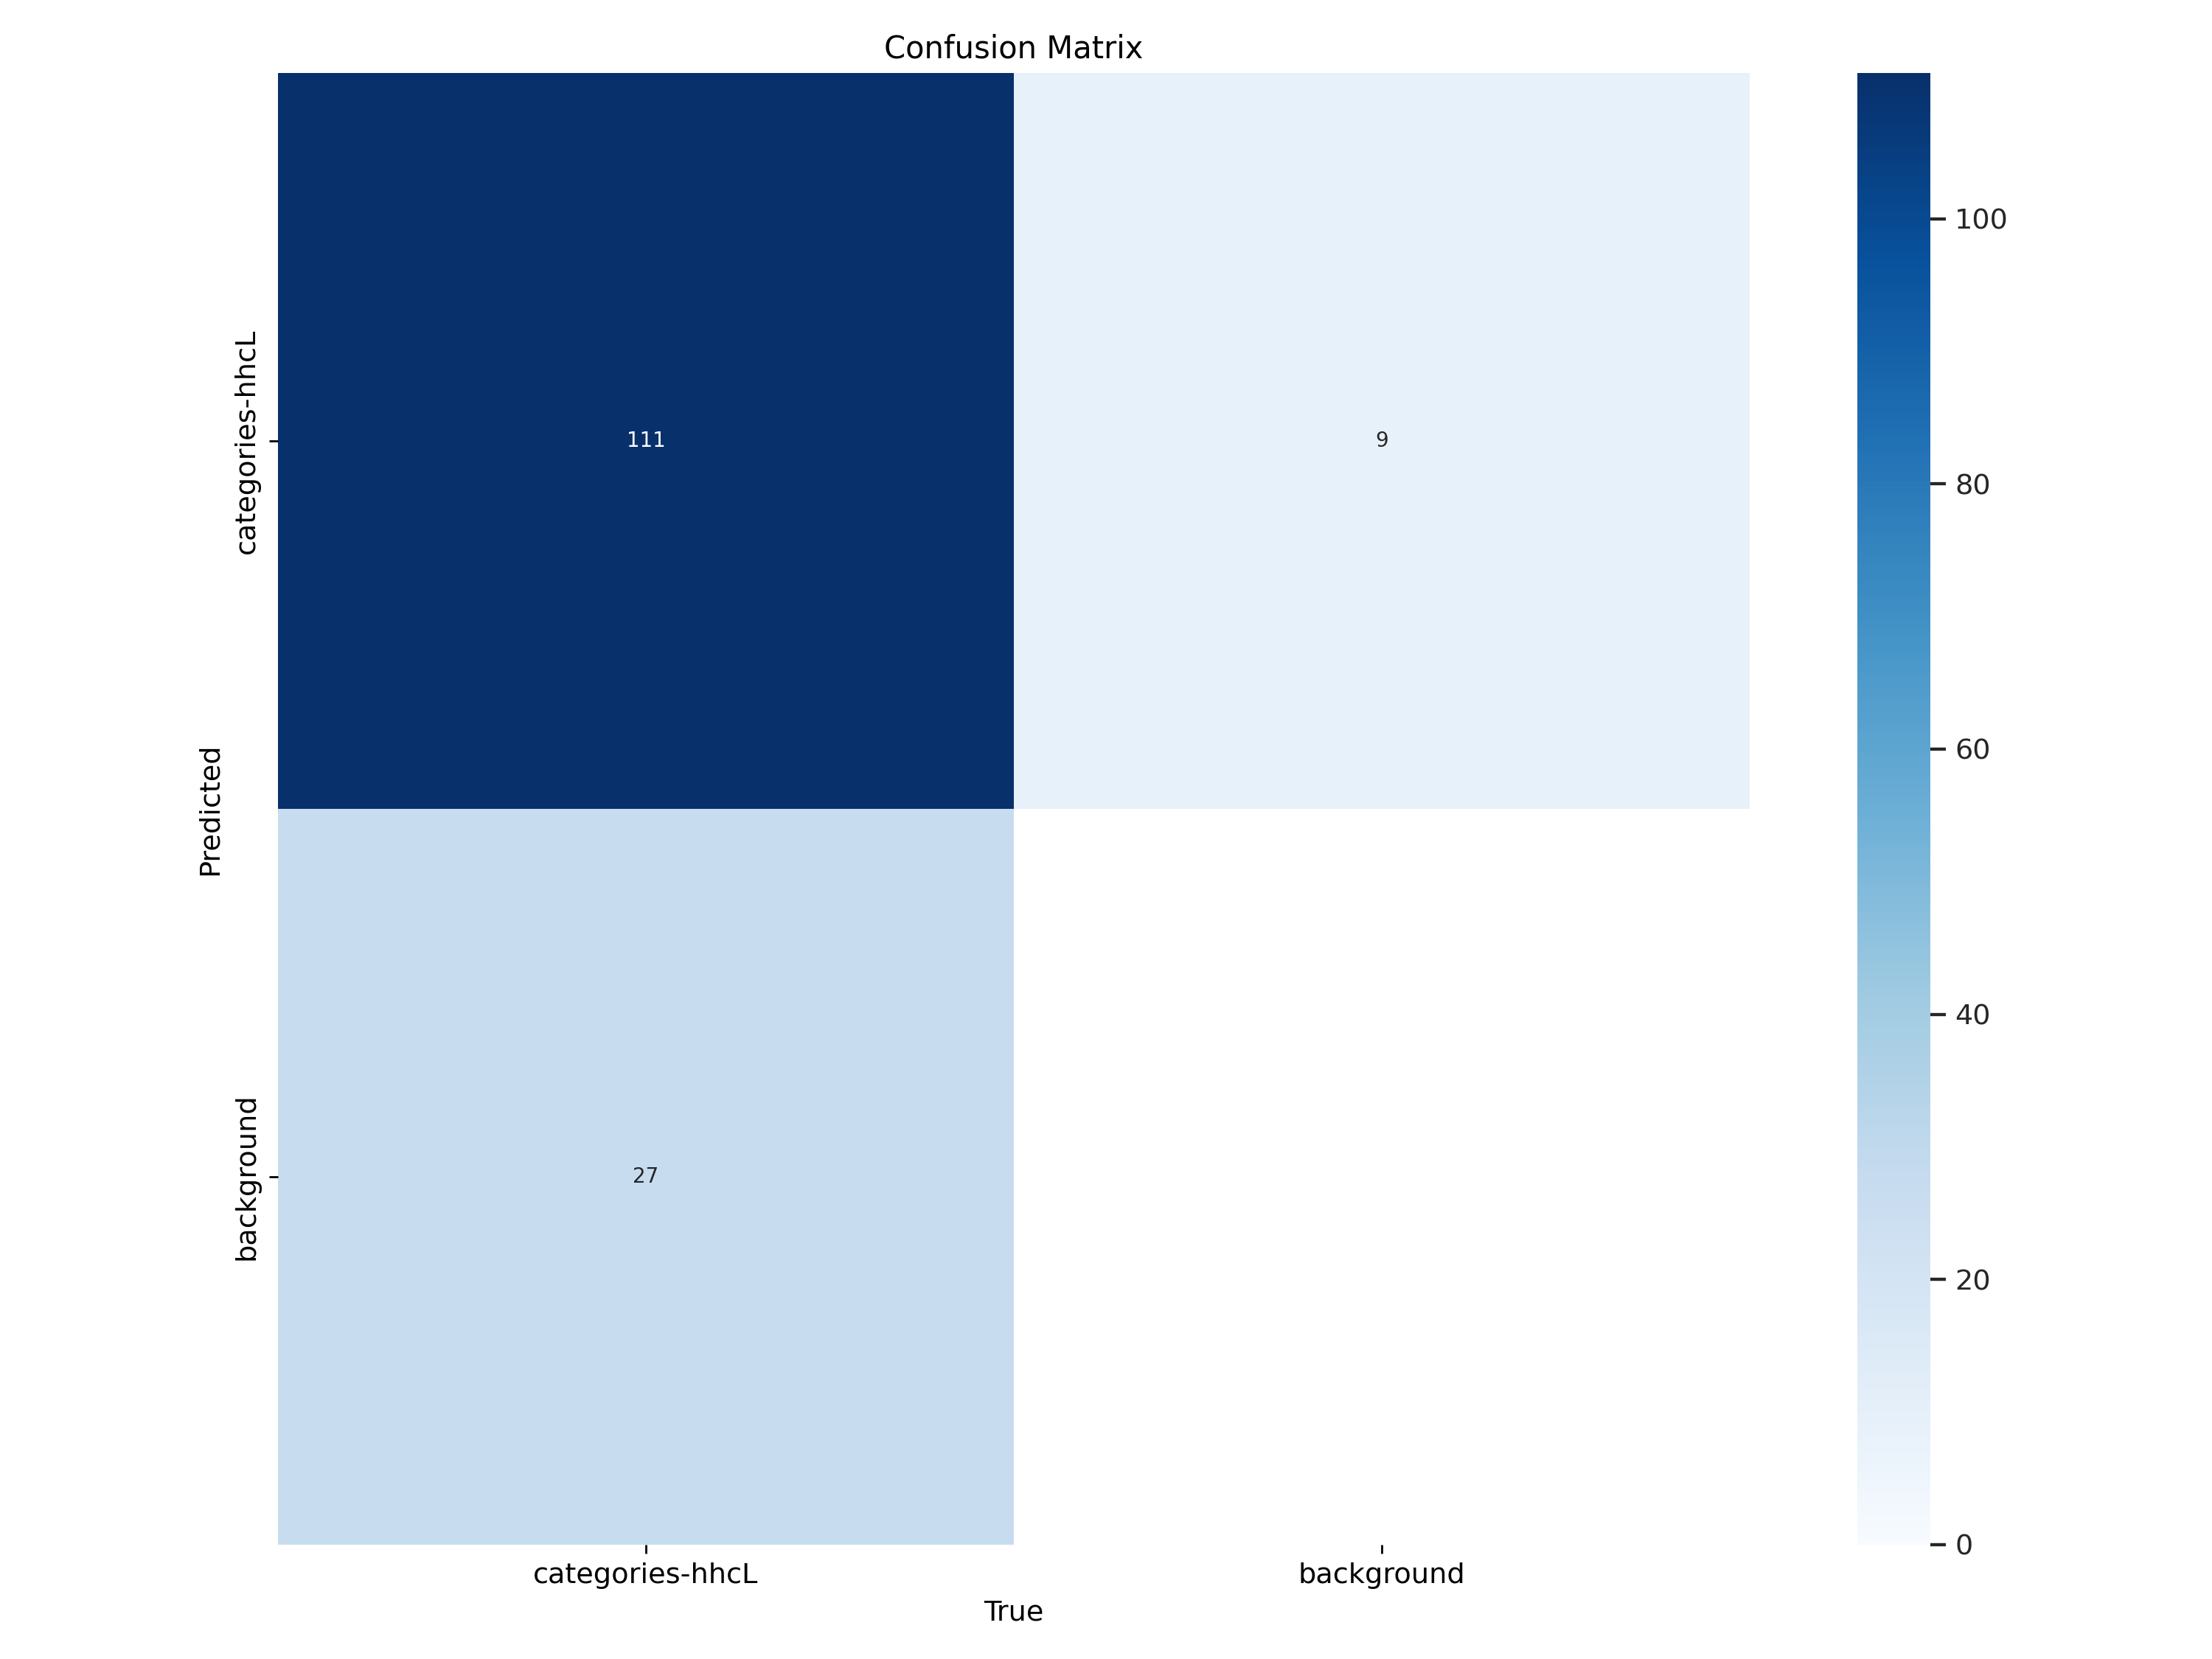

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/confusion_matrix.png', width=600)

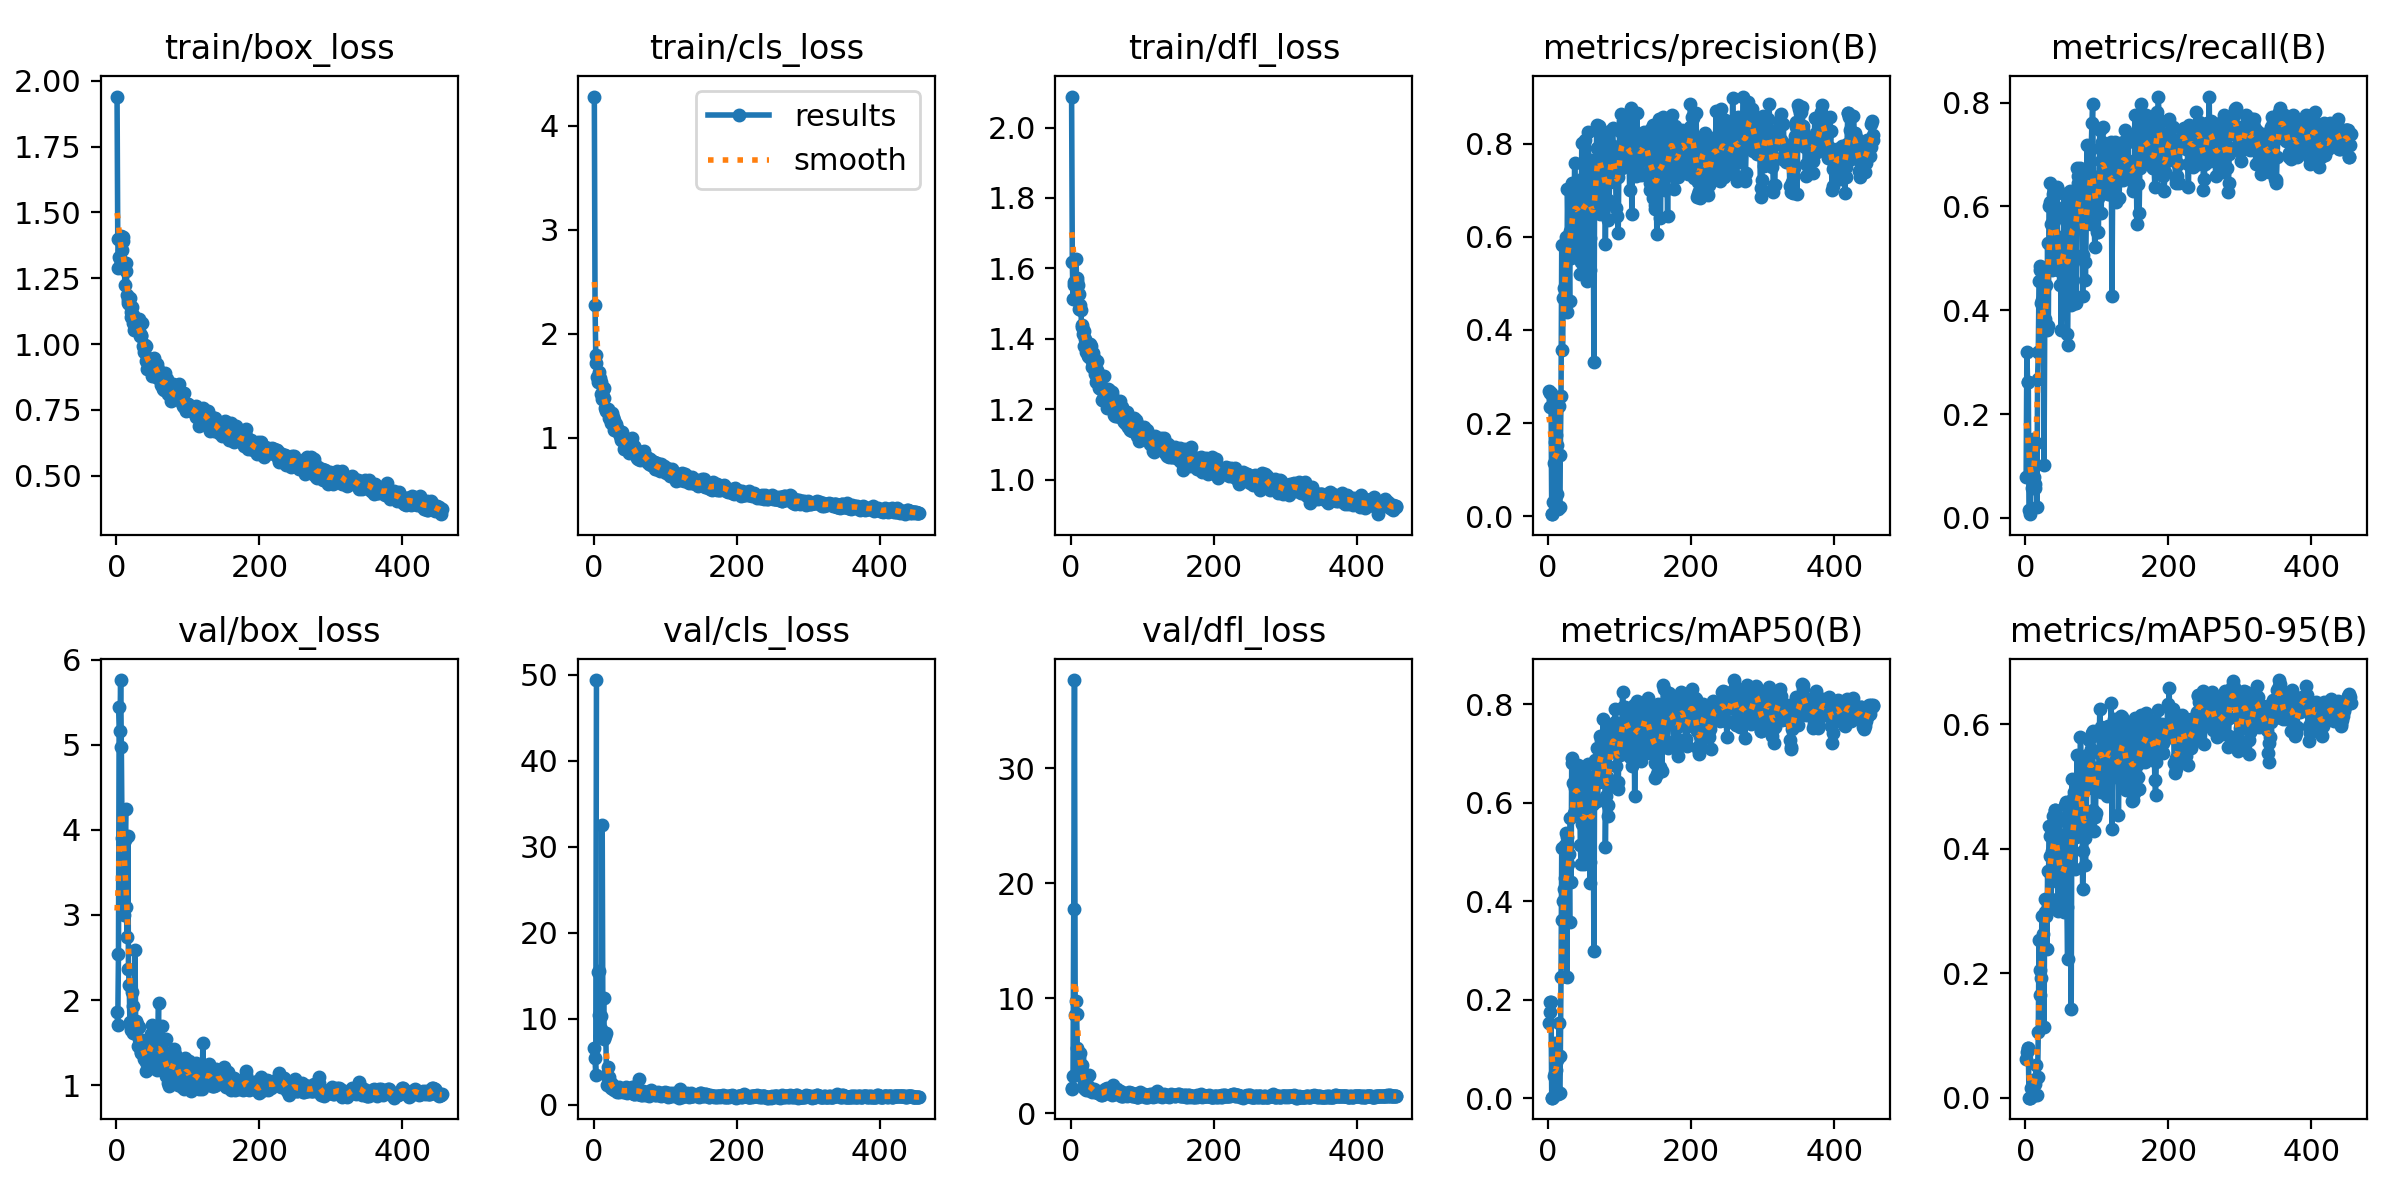

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/results.png', width=600)

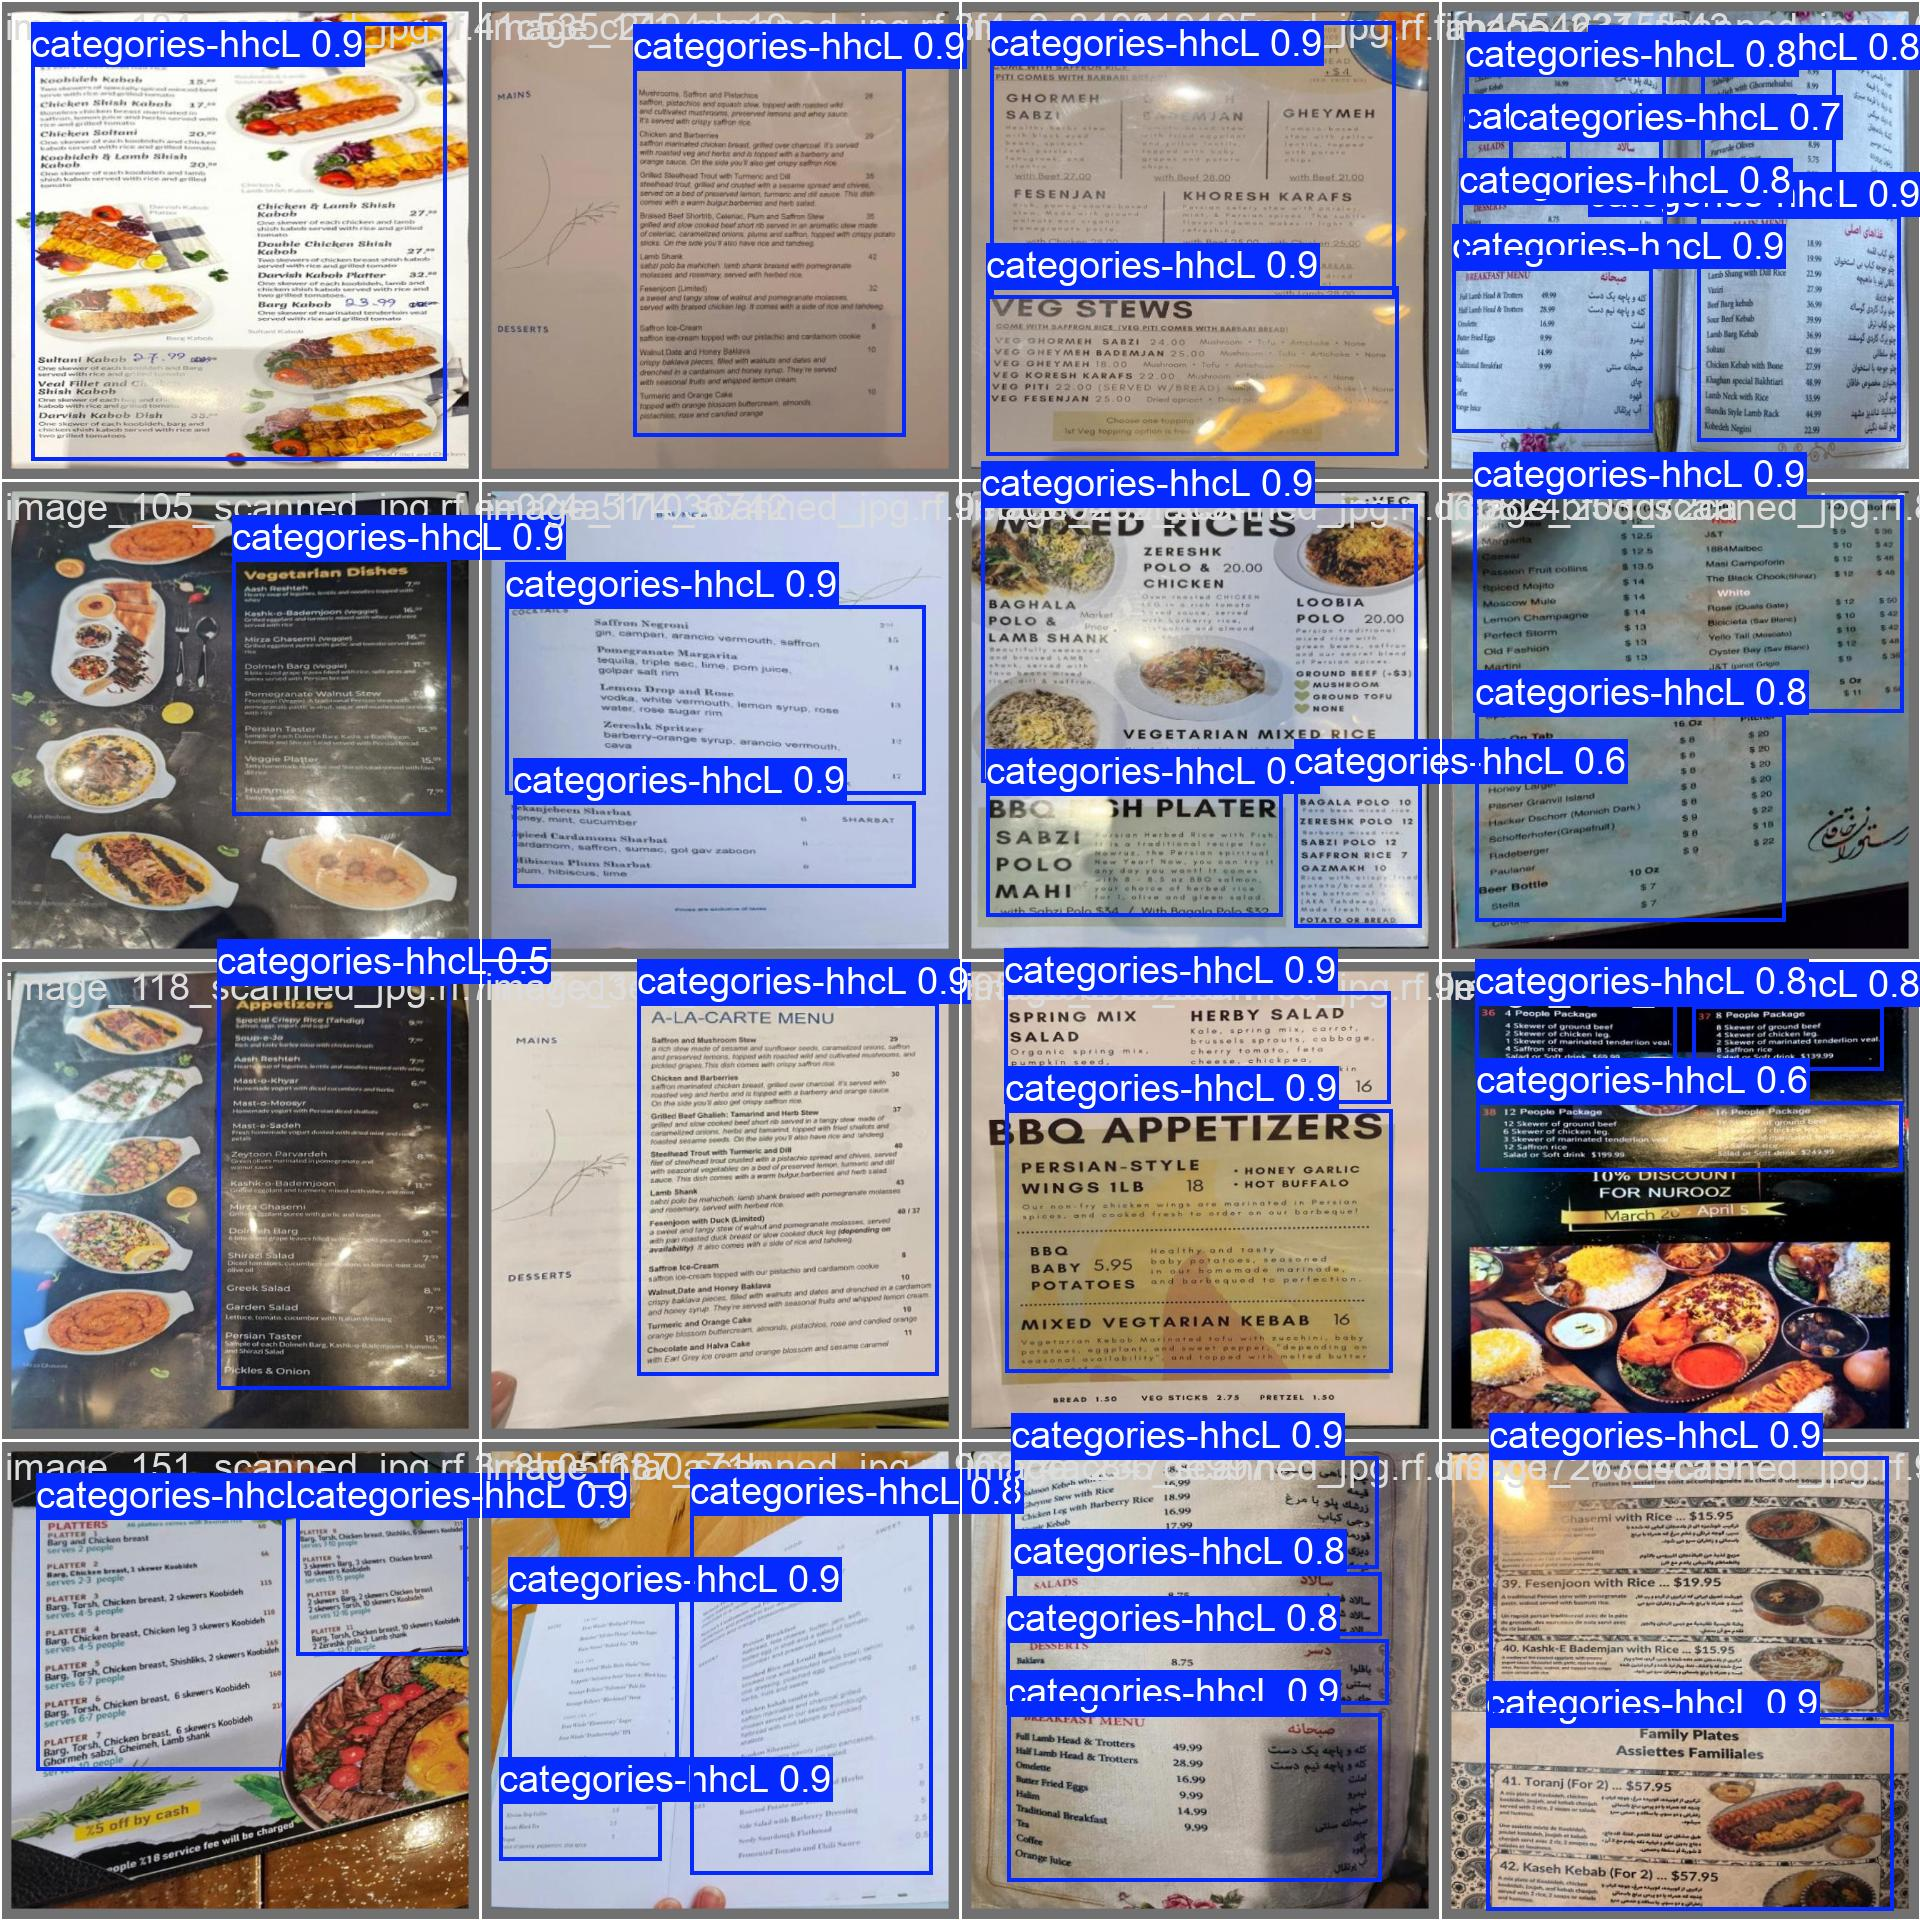

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

## Validate fine-tuned model

In [ ]:
!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml conf=0.5 iou=0.3 save_conf=True save_txt=True

Ultralytics 8.3.40 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs
val: Scanning /content/datasets/category_detection-1/valid/labels.cache... 58 images, 0 backgrounds, 0 corrupt: 100% 58/58 [00:00<?, ?it/s]
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 23, len(boxes) = 138. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% 4/4 [00:03<00:00,  1.14it/s]
                   all         58        138      0.878      0.783      0.842      0.672
Speed: 10.8ms preprocess, 17.0ms inference, 0.0ms loss, 5.9ms postprocess per image
Results saved to runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/val


## Inference with custom model

In [ ]:
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.5 iou=0.3 source={dataset.location}/test/images save=True save_conf=True save_txt=True

Ultralytics 8.3.40 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs

image 1/29 /content/datasets/category_detection-1/test/images/image_107_scanned_jpg.rf.4f24dca6aa75cb545eb0e541c44873f4.jpg: 640x640 2 categories-hhcLs, 15.6ms
image 2/29 /content/datasets/category_detection-1/test/images/image_113_scanned_jpg.rf.9729bd2996a8848bd9d8e81a254df8f4.jpg: 640x640 6 categories-hhcLs, 15.6ms
image 3/29 /content/datasets/category_detection-1/test/images/image_129_scanned_jpg.rf.19c9091b0c642e1c93791876f487c7dc.jpg: 640x640 3 categories-hhcLs, 15.6ms
image 4/29 /content/datasets/category_detection-1/test/images/image_130_scanned_jpg.rf.a2d9c23b91c300bdc328578a656ddfbd.jpg: 640x640 4 categories-hhcLs, 15.6ms
image 5/29 /content/datasets/category_detection-1/test/images/image_144_scanned_jpg.rf.8c8bc56a384ece9e6a8959e4e5cb6510.jpg: 640x640 2 categories-hhcLs, 15.6ms
image 6/29 /content/datasets/cate

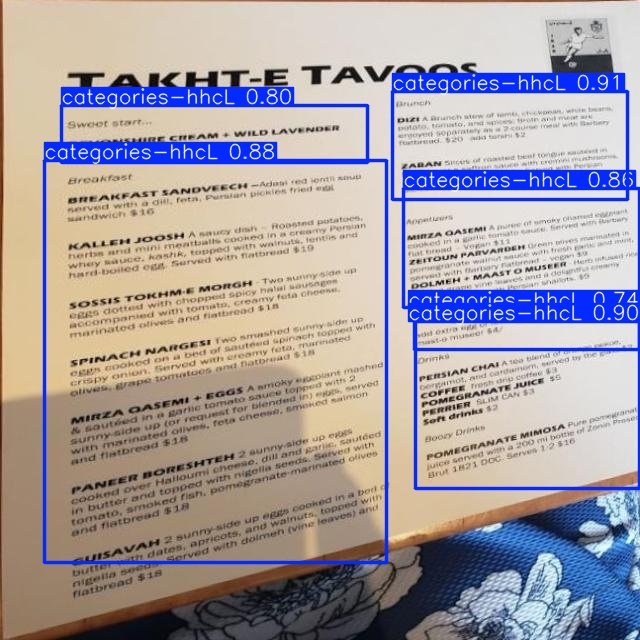

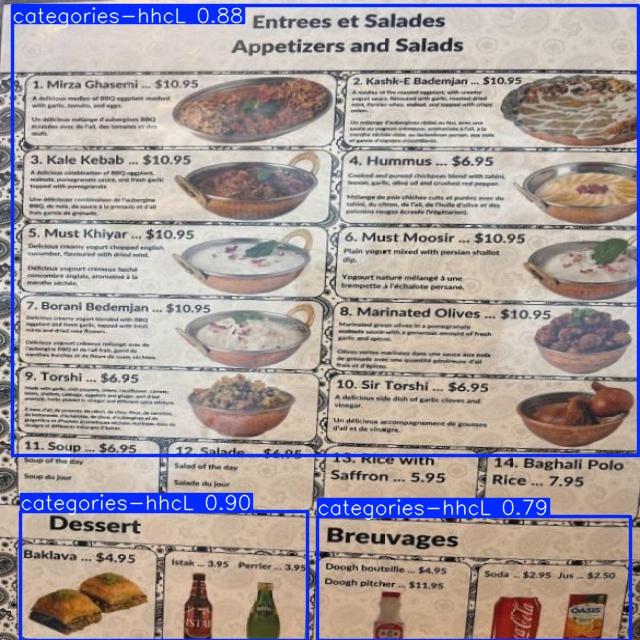

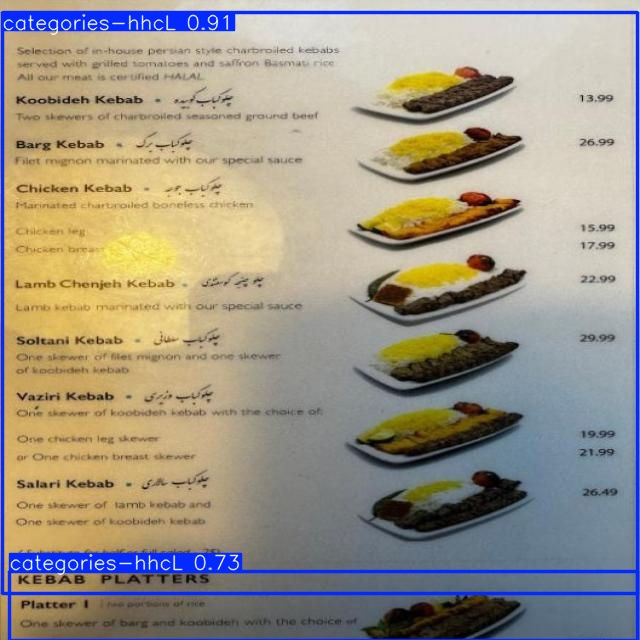

In [ ]:
import glob
import os
from IPython.display import Image as IPyImage, display

latest_folder = max(glob.glob(f'{HOME}/runs/detect/predict*/'), key=os.path.getmtime)
for img in glob.glob(f'{latest_folder}/*.jpg')[:3]:
    display(IPyImage(filename=img, width=600))
    print("\n")